In [ ]:
# 転移学習
# 学習済みモデルの線形層（全結合層）のみを付け替えて学習を行う
# 重みづけの更新（勾配計算）があるものをファインチューニングという（転移学習の一種）

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

In [2]:
device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() # Mac用のGPU
    else "cpu"
)
device

'mps'

In [8]:
# データセットのダウンロード
!wget https://download.pytorch.org/tutorial/hymenoptera_data.zip

--2026-11-03 12:13:12--  https://download.pytorch.org/tutorial/hymenoptera_data.zip
Resolving download.pytorch.org (download.pytorch.org)... 99.84.141.46, 99.84.141.120, 99.84.141.56, ...
Connecting to download.pytorch.org (download.pytorch.org)|99.84.141.46|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47286322 (45M) [application/zip]
Saving to: ‘hymenoptera_data.zip’

hymenoptera_data.zi 100%[===================>]  45.10M  62.6MB/s    in 0.7s    

2026-11-03 12:13:13 (62.6 MB/s) - ‘hymenoptera_data.zip’ saved [47286322/47286322]



In [9]:
# 前処理
transform = transforms.Compose([
    transforms.Resize((224, 224)), # 画像の高さと幅を揃える
    transforms.ToTensor(),
    transforms.Normalize((0.5, ), (0.5, ))
])

In [10]:
train_dataset = datasets.ImageFolder(
    "./data/hymenoptera_data/train",
    transform=transform
)

In [12]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

In [14]:
data_iter = iter(train_loader)
imgs, labels = next(data_iter)
imgs.size(), labels

(torch.Size([32, 3, 224, 224]),
 tensor([0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
         0, 1, 0, 0, 1, 0, 0, 0]))

In [33]:
model = models.resnet18(pretrained=True)
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [34]:
for param in model.parameters():
    param.requires_grad = False # 勾配計算をしない

In [35]:
model.fc = nn.Linear(in_features=512, out_features=2)
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [36]:
criterion = nn.CrossEntropyLoss()
# 最適化は、付け替えた FC の層だけにする
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [37]:
num_epochs = 15
losses = []
accs = []
for epoch in range(num_epochs):
    running_loss = 0.0
    running_acc = 0.0
    for imgs, labels in train_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        output = model(imgs)
        loss = criterion(output, labels)
        running_loss += loss.item()
        pred = torch.argmax(output, dim=1)
        running_acc += torch.mean(pred.eq(labels).float()).item()
        loss.backward()
        optimizer.step()
    running_loss /= len(train_loader)
    running_acc /= len(train_loader)
    losses.append(running_loss)
    accs.append(running_acc)
    print("epoch: {}, loss: {}, acc: {}".format(epoch, running_loss, running_acc))

epoch: 0, loss: 0.641914613544941, acc: 0.6265624985098839
epoch: 1, loss: 0.45323479175567627, acc: 0.8390624970197678
epoch: 2, loss: 0.3336431533098221, acc: 0.9390624985098839
epoch: 3, loss: 0.2789050154387951, acc: 0.9296875
epoch: 4, loss: 0.2418464682996273, acc: 0.9507812485098839
epoch: 5, loss: 0.21201312355697155, acc: 0.9742187485098839
epoch: 6, loss: 0.19720622710883617, acc: 0.9546874985098839
epoch: 7, loss: 0.19439188577234745, acc: 0.9656250029802322
epoch: 8, loss: 0.18559205625206232, acc: 0.93359375
epoch: 9, loss: 0.1753253173083067, acc: 0.9624999985098839
epoch: 10, loss: 0.15186732448637486, acc: 0.9703124985098839
epoch: 11, loss: 0.1576852025464177, acc: 0.9523437470197678
epoch: 12, loss: 0.14811841771006584, acc: 0.9460937529802322
epoch: 13, loss: 0.14524239394813776, acc: 0.9507812485098839
epoch: 14, loss: 0.13304435461759567, acc: 0.9562499970197678


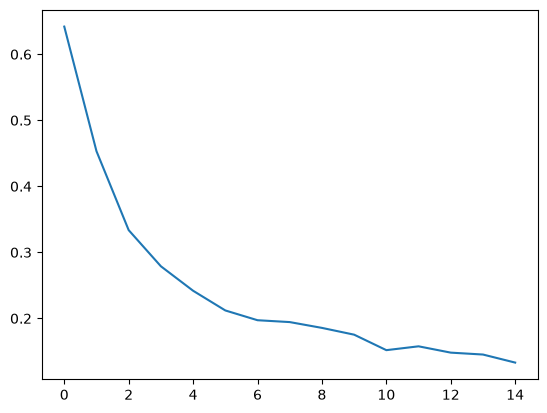

In [38]:
plt.plot(losses)

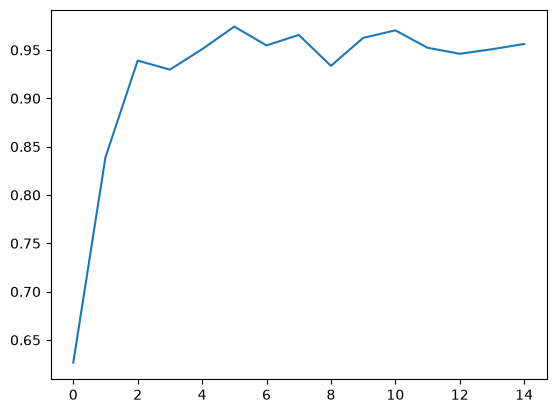

In [39]:
plt.plot(accs)